In [ ]:
import os
import cv2
import ast
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

chemin_fichier_texte = 'dataset_complet_citrons.txt' 
with open(chemin_fichier_texte, 'r', encoding='utf-8') as f:
    contenu = f.read()
    donnees_citrons = ast.literal_eval(contenu)

dictionnaire_volumes = {item["Spécimen"]: item["Volume_cm3"] for item in donnees_citrons}

def extraire_features_image(chemin_image):
    """
    Lit une image, segmente le citron et extrait ses caractéristiques géométriques en pixels.
    """
    img = cv2.imread(chemin_image)
    if img is None:
        return None
        
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if not contours:
        return None
        
    contour_principal = max(contours, key=cv2.contourArea)
    
    surface_pixels = cv2.contourArea(contour_principal)
    perimetre_pixels = cv2.arcLength(contour_principal, True)
    
    x, y, w, h = cv2.boundingRect(contour_principal)
    surface_bounding_box = w * h
    ratio_aspect = float(w) / h if h != 0 else 0
    
    return [surface_pixels, perimetre_pixels, surface_bounding_box, ratio_aspect]

dossier_images = 'dataset_images_final'
X = []
y = []

for nom_fichier in os.listdir(dossier_images):
    chemin_complet = os.path.join(dossier_images, nom_fichier)
    
    try:
        numero_specimen = int(''.join(filter(str.isdigit, nom_fichier)))
    except ValueError:
        continue 
        
    if numero_specimen in dictionnaire_volumes:
        features = extraire_features_image(chemin_complet)
        if features is not None:
            X.append(features)
            y.append(dictionnaire_volumes[numero_specimen])

X = np.array(X)
y = np.array(y)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

modele_rf = RandomForestRegressor(n_estimators=100, random_state=42)
modele_rf.fit(X_train_scaled, y_train)

y_pred = modele_rf.predict(X_test_scaled)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Erreur Quadratique Moyenne (MSE) : {mse:.2f}")
print(f"Score R2 (Précision globale) : {r2:.2f}")

Erreur Quadratique Moyenne (MSE) : 4043.11
Score R2 (Précision globale) : -0.13


In [ ]:
def predire_volume_citron(chemin_nouvelle_image, modele, scaler):
    """
    Reçoit l'image d'un nouveau citron et retourne son volume estimé.
    """
    features_brutes = extraire_features_image(chemin_nouvelle_image)
    
    if features_brutes is None:
        return "Erreur : Impossible de détecter un citron sur l'image."
        
    features_brutes = np.array(features_brutes).reshape(1, -1)
    
    features_scaled = scaler.transform(features_brutes)
    
    volume_estime = modele.predict(features_scaled)[0]
    
    return volume_estime

Le volume estimé du citron est de 249.40 cm³


In [ ]:
import os

dossier_test = r"C:\Users\T490\OneDrive\Desktop\malki\dataset_images_final"

print(f"{'Spécimen':<10} | {'Vrai Vol (cm³)':<15} | {'Vol Prédit (cm³)':<18} | {'Erreur Rel (%)':<15}")
print("-" * 65)

erreurs_relatives = []

for i in range(1, 16):
    nom_fichier = f"citron_{i:03d}.jpg"
    chemin_test = os.path.join(dossier_test, nom_fichier)
    
    if not os.path.exists(chemin_test):
        chemin_test = os.path.join(dossier_test, f"citron_{i}.jpg")
        
    if not os.path.exists(chemin_test):
        print(f"{i:<10} | Image introuvable")
        continue
        
    if i not in dictionnaire_volumes:
        print(f"{i:<10} | Volume réel inconnu")
        continue
        
    vrai_volume = dictionnaire_volumes[i]
    
    volume_predit = predire_volume_citron(chemin_test, modele_rf, scaler)
    
    if isinstance(volume_predit, str):
        print(f"{i:<10} | Échec détection (Image illisible)")
        continue
        
    erreur_rel = abs(volume_predit - vrai_volume) / vrai_volume * 100
    erreurs_relatives.append(erreur_rel)
    
    print(f"{i:<10} | {vrai_volume:<15.2f} | {volume_predit:<18.2f} | {erreur_rel:<15.2f}%")

if erreurs_relatives:
    erreur_moyenne = sum(erreurs_relatives) / len(erreurs_relatives)
    print("-" * 65)
    print(f" Bilan : Erreur relative moyenne sur ces {len(erreurs_relatives)} citrons = {erreur_moyenne:.2f}%")

Spécimen   | Vrai Vol (cm³)  | Vol Prédit (cm³)   | Erreur Rel (%) 
-----------------------------------------------------------------
1          | 194.35          | 188.97             | 2.77           %
2          | 185.90          | 188.97             | 1.65           %
3          | 253.50          | 213.28             | 15.87          %
4          | 290.30          | 249.40             | 14.09          %
5          | 304.80          | 247.01             | 18.96          %
6          | 228.15          | 198.77             | 12.88          %
7          | 169.00          | 176.98             | 4.72           %
8          | 185.90          | 205.48             | 10.53          %
9          | 152.10          | 159.30             | 4.73           %
10         | 154.40          | 187.66             | 21.54          %
11         | 135.20          | 210.08             | 55.38          %
12         | 116.95          | 144.93             | 23.92          %
13         | 135.00          | 192.44 

In [ ]:
import os
import cv2
import numpy as np
import math

def calculer_volume_disques_pixels(chemin_image):
    """
    Calcule le volume d'un citron en pixels cubes par la méthode des disques.
    Retourne le volume ou None en cas d'erreur.
    """
    img = cv2.imread(chemin_image)
    if img is None:
        return None

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if not contours:
        return None
        
    contour_principal = max(contours, key=cv2.contourArea)
    
    mask = np.zeros_like(gray)
    cv2.drawContours(mask, [contour_principal], -1, 255, thickness=cv2.FILLED)

    x, y, w, h = cv2.boundingRect(contour_principal)
    citron_mask = mask[y:y+h, x:x+w]

    if h > w:
        citron_mask = cv2.rotate(citron_mask, cv2.ROTATE_90_CLOCKWISE)
        w, h = h, w 

    volume_pixels_cubes = 0

    for i in range(w):
        colonne = citron_mask[:, i]
        diametre_pixels = np.sum(colonne == 255)
        
        if diametre_pixels > 0:
            rayon = diametre_pixels / 2.0
            volume_cylindre = math.pi * (rayon ** 2) * 1
            volume_pixels_cubes += volume_cylindre

    return volume_pixels_cubes


dossier_images = r"C:\Users\T490\OneDrive\Desktop\malki\dataset_images_final"
donnees_volumes_pixels = []

print(" Début du traitement des images...")

for nom_fichier in os.listdir(dossier_images):
    chemin_complet = os.path.join(dossier_images, nom_fichier)
    
    if not nom_fichier.lower().endswith(('.png', '.jpg', '.jpeg')):
        continue
        
    try:
        numero_specimen = int(''.join(filter(str.isdigit, nom_fichier)))
    except ValueError:
        print(f" Impossible d'extraire un numéro pour : {nom_fichier}")
        continue 
        
    volume_px3 = calculer_volume_disques_pixels(chemin_complet)
    
    if volume_px3 is not None:
        donnees_volumes_pixels.append({
            "Spécimen": numero_specimen,
            "Volume_px3": volume_px3
        })
    else:
        print(f" Échec de l'analyse pour l'image : {nom_fichier}")

donnees_volumes_pixels = sorted(donnees_volumes_pixels, key=lambda k: k['Spécimen'])

print(f" Traitement terminé ! {len(donnees_volumes_pixels)} citrons analysés avec succès.")

print("\n Aperçu des 5 premiers résultats :")
for item in donnees_volumes_pixels[:5]:
    print(f"Spécimen {item['Spécimen']:>3} : {item['Volume_px3']:>15,.2f} pixels³")

⏳ Début du traitement des images...
✅ Traitement terminé ! 109 citrons analysés avec succès.

🔍 Aperçu des 5 premiers résultats :
Spécimen   1 :   26,922,775.96 pixels³
Spécimen   2 :   26,922,775.96 pixels³
Spécimen   3 :   23,856,609.01 pixels³
Spécimen   4 :   29,930,653.79 pixels³
Spécimen   5 :   29,871,416.70 pixels³


In [ ]:
import ast
import json

fichier_entree = 'dataset_complet_citrons.txt'
fichier_sortie = 'dataset_complet_citrons_avec_pixels.txt'

if 'donnees_volumes_pixels' not in locals() or len(donnees_volumes_pixels) < 10:
    print(" Erreur : La liste 'donnees_volumes_pixels' est vide ou introuvable.")
    print("Veuillez d'abord réexécuter la cellule qui calcule les volumes sur toutes les images !")
else:
    dict_recherche_pixels = {item["Spécimen"]: item["Volume_px3"] for item in donnees_volumes_pixels}

    with open(fichier_entree, 'r', encoding='utf-8') as f:
        contenu = f.read()
        index_debut_liste = contenu.find('[')
        if index_debut_liste != -1:
            contenu_nettoye = contenu[index_debut_liste:]
            dataset_original = ast.literal_eval(contenu_nettoye)
        else:
            raise ValueError("Erreur : Impossible de trouver la liste dans le fichier source.")

    dataset_enrichi = []

    for citron in dataset_original:
        nouveau_citron = citron.copy()
        numero_specimen = nouveau_citron["Spécimen"]
        
        if numero_specimen in dict_recherche_pixels:
            nouveau_citron["Volume_px3"] = round(dict_recherche_pixels[numero_specimen], 2)
        else:
            nouveau_citron["Volume_px3"] = None
            print(f" Attention : Aucun volume en pixels trouvé pour le Spécimen {numero_specimen}")
            
        dataset_enrichi.append(nouveau_citron)

    with open(fichier_sortie, 'w', encoding='utf-8') as f:
        json.dump(dataset_enrichi, f, ensure_ascii=False, indent=4)

    print(f" Succès total ! Le fichier '{fichier_sortie}' a été créé avec {len(dataset_enrichi)} citrons.")

✅ Succès total ! Le fichier 'dataset_complet_citrons_avec_pixels.txt' a été créé avec 100 citrons.


In [ ]:
import os
import cv2
import json
import numpy as np
import math
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score


def calculer_volume_disques_pixels(chemin_image):
    """Calcule le volume en pixels cubes par la méthode des disques."""
    img = cv2.imread(chemin_image)
    if img is None:
        return None

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if not contours: return None
        
    contour_principal = max(contours, key=cv2.contourArea)
    mask = np.zeros_like(gray)
    cv2.drawContours(mask, [contour_principal], -1, 255, thickness=cv2.FILLED)

    x, y, w, h = cv2.boundingRect(contour_principal)
    citron_mask = mask[y:y+h, x:x+w]

    if h > w:
        citron_mask = cv2.rotate(citron_mask, cv2.ROTATE_90_CLOCKWISE)
        w, h = h, w 

    volume_pixels_cubes = 0
    for i in range(w):
        colonne = citron_mask[:, i]
        diametre_pixels = np.sum(colonne == 255)
        if diametre_pixels > 0:
            rayon = diametre_pixels / 2.0
            volume_pixels_cubes += math.pi * (rayon ** 2) * 1

    return volume_pixels_cubes


fichier_donnees = 'dataset_complet_citrons_avec_pixels.txt'

X = []
y = []

with open(fichier_donnees, 'r', encoding='utf-8') as f:
    dataset = json.load(f)

for citron in dataset:
    vol_px3 = citron.get("Volume_px3")
    masse = citron.get("Masse_g")
    longueur = citron.get("Longueur_cm")
    dmax = citron.get("Dmax_cm")
    vol_reel = citron.get("Volume_cm3")
    
    if None not in (vol_px3, masse, longueur, dmax, vol_reel):
        X.append([vol_px3, masse, longueur, dmax])
        y.append(vol_reel)

X = np.array(X, dtype=float)
y = np.array(y, dtype=float)

print(f" Entraînement sur {len(X)} citrons valides.")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

modele_hybride = RandomForestRegressor(n_estimators=100, random_state=42)
modele_hybride.fit(X_train_scaled, y_train)

y_pred = modele_hybride.predict(X_test_scaled)
print(f" Erreur Quadratique (MSE) : {mean_squared_error(y_test, y_pred):.2f}")
print(f" Précision globale (R2)   : {r2_score(y_test, y_pred):.3f}")


def predire_volume_hybride(chemin_image, masse_g, longueur_cm, dmax_cm, modele, scaler):
    """
    Estime le volume réel en fusionnant l'analyse de l'image (pixels) 
    et les mesures physiques réelles de l'utilisateur.
    """
    vol_px3 = calculer_volume_disques_pixels(chemin_image)
    
    if vol_px3 is None:
        return "Erreur : Impossible de traiter l'image du citron."
    
    features_brutes = np.array([vol_px3, masse_g, longueur_cm, dmax_cm]).reshape(1, -1)
    
    features_scaled = scaler.transform(features_brutes)
    
    volume_estime = modele.predict(features_scaled)[0]
    
    return volume_estime

✅ Entraînement sur 100 citrons valides.
📊 Erreur Quadratique (MSE) : 77.86
📊 Précision globale (R2)   : 0.978


In [ ]:
chemin_test = "C:\\Users\\T490\\OneDrive\\Desktop\\malki\\dataset_images_final\\citron_003.jpg" 
masse_mesuree = 208.36
longueur_mesuree = 9.5
dmax_mesure = 7.1

if os.path.exists(chemin_test):
    volume_final = predire_volume_hybride(chemin_test, masse_mesuree, longueur_mesuree, dmax_mesure, modele_hybride, scaler)
    print(f"\n🍋 Résultat de la prédiction hybride : {volume_final:.2f} cm³")
else:
    print(f"\n Image introuvable pour le test.")


🍋 Résultat de la prédiction hybride : 256.77 cm³


In [ ]:
import os

dossier_test = r"C:\\Users\\T490\\OneDrive\\Desktop\\malki\\dataset_images_final"

print(f"{'Spécimen':<10} | {'Vrai Vol (cm³)':<15} | {'Vol Prédit (cm³)':<18} | {'Erreur Rel (%)':<15}")
print("-" * 65)

erreurs_relatives = []

for citron in dataset[:15]:
    numero = citron.get("Spécimen")
    masse_mesuree = citron.get("Masse_g")
    longueur_mesuree = citron.get("Longueur_cm")
    dmax_mesure = citron.get("Dmax_cm")
    vrai_volume = citron.get("Volume_cm3")
    
    if None in (numero, masse_mesuree, longueur_mesuree, dmax_mesure, vrai_volume):
        print(f"{numero:<10} |  Données physiques incomplètes")
        continue

    nom_fichier = f"citron_{numero:03d}.jpg"
    chemin_test = os.path.join(dossier_test, nom_fichier)
    
    if not os.path.exists(chemin_test):
        chemin_test = os.path.join(dossier_test, f"citron_{numero}.jpg")
        
    if not os.path.exists(chemin_test):
        print(f"{numero:<10} |  Image introuvable")
        continue
        
    volume_predit = predire_volume_hybride(chemin_test, masse_mesuree, longueur_mesuree, dmax_mesure, modele_hybride, scaler)
    
    if isinstance(volume_predit, str):
        print(f"{numero:<10} |  Échec OpenCV (Image illisible)")
        continue
        
    erreur_rel = abs(volume_predit - vrai_volume) / vrai_volume * 100
    erreurs_relatives.append(erreur_rel)
    
    print(f"{numero:<10} | {vrai_volume:<15.2f} | {volume_predit:<18.2f} | {erreur_rel:<15.2f}%")

if erreurs_relatives:
    erreur_moyenne = sum(erreurs_relatives) / len(erreurs_relatives)
    print("-" * 65)
    print(f" Bilan : Erreur relative moyenne sur {len(erreurs_relatives)} citrons = {erreur_moyenne:.2f}%")
else:
    print("\n Aucun test n'a pu aboutir. Vérifiez le chemin de vos images.")

Spécimen   | Vrai Vol (cm³)  | Vol Prédit (cm³)   | Erreur Rel (%) 
-----------------------------------------------------------------
1          | 194.35          | 194.14             | 0.11           %
2          | 185.90          | 175.24             | 5.73           %
3          | 253.50          | 256.77             | 1.29           %
4          | 290.30          | 288.68             | 0.56           %
5          | 304.80          | 297.62             | 2.35           %
6          | 228.15          | 228.64             | 0.21           %
7          | 169.00          | 172.02             | 1.78           %
8          | 185.90          | 186.86             | 0.52           %
9          | 152.10          | 154.78             | 1.76           %
10         | 154.40          | 139.94             | 9.36           %
11         | 135.20          | 166.84             | 23.41          %
12         | 116.95          | 114.81             | 1.83           %
13         | 135.00          | 128.14 

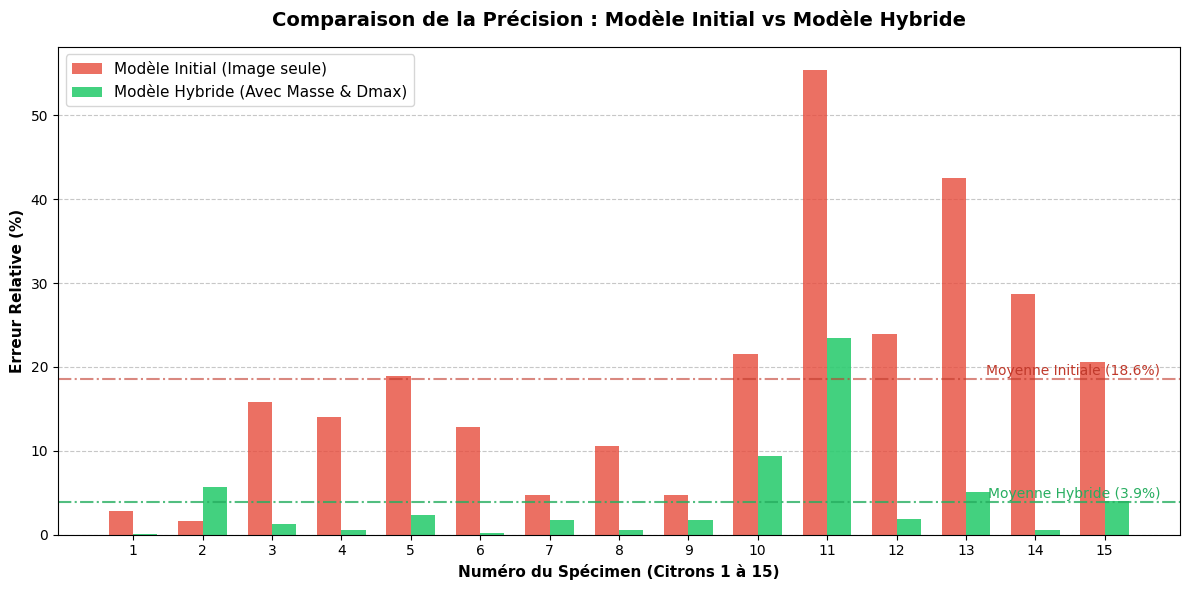

In [55]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Définition des données extraites de vos captures d'écran
specimens = np.arange(1, 16) # De 1 à 15

# Erreurs relatives (%) du Modèle 1 (Image seule - 18.59% en moyenne)
erreurs_modele_initial = [
    2.77, 1.65, 15.87, 14.09, 18.96, 12.88, 4.72, 10.53, 
    4.73, 21.54, 55.38, 23.92, 42.55, 28.75, 20.57
]

# Erreurs relatives (%) du Modèle 2 (Hybride - 3.91% en moyenne)
erreurs_modele_hybride = [
    0.11, 5.73, 1.29, 0.56, 2.35, 0.21, 1.78, 0.52, 
    1.76, 9.36, 23.41, 1.83, 5.08, 0.61, 4.02
]

# 2. Configuration des paramètres du graphique
largeur_barre = 0.35
x = np.arange(len(specimens))  # Position des spécimens sur l'axe X

fig, ax = plt.subplots(figsize=(12, 6))

# 3. Tracé des deux séries de barres
barres1 = ax.bar(x - largeur_barre/2, erreurs_modele_initial, largeur_barre, 
                 label='Modèle Initial (Image seule)', color='#e74c3c', alpha=0.8)

barres2 = ax.bar(x + largeur_barre/2, erreurs_modele_hybride, largeur_barre, 
                 label='Modèle Hybride (Avec Masse & Dmax)', color='#2ecc71', alpha=0.9)

# 4. Esthétique et annotations
ax.set_xlabel('Numéro du Spécimen (Citrons 1 à 15)', fontweight='bold', fontsize=11)
ax.set_ylabel("Erreur Relative (%)", fontweight='bold', fontsize=11)
ax.set_title("Comparaison de la Précision : Modèle Initial vs Modèle Hybride", 
             fontweight='bold', fontsize=14, pad=15)

ax.set_xticks(x)
ax.set_xticklabels(specimens)
ax.legend(fontsize=11)

# Ajout d'une grille horizontale pour faciliter la lecture
ax.yaxis.grid(True, linestyle='--', alpha=0.7)
ax.set_axisbelow(True)

# Ajout des lignes de moyennes pour montrer la différence globale
plt.axhline(y=18.59, color='#c0392b', linestyle='-.', linewidth=1.5, alpha=0.6)
plt.axhline(y=3.91, color='#27ae60', linestyle='-.', linewidth=1.5, alpha=0.8)
plt.text(14.8, 19.5, 'Moyenne Initiale (18.6%)', color='#c0392b', ha='right', va='center')
plt.text(14.8, 4.8, 'Moyenne Hybride (3.9%)', color='#27ae60', ha='right', va='center')

# 5. Affichage propre
plt.tight_layout()
plt.show()